In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("titanic_train.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

First five rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

In [4]:
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nSurvival counts:")
print(df["Survived"].value_counts())

Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64


In [5]:
# Select the features and target
features = ["Pclass", "Age", "Sex", "Fare"]

X = df[features].copy()
y = df["Survived"]

# Convert sex to numeric values
X["Sex"] = X["Sex"].map({
    "male": 0,
    "female": 1
})

print("Features before missing-value handling:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

Features before missing-value handling:
   Pclass   Age  Sex     Fare
0       3  22.0    0   7.2500
1       1  38.0    1  71.2833
2       3  26.0    1   7.9250
3       1  35.0    1  53.1000
4       3  35.0    0   8.0500

Missing values:
Pclass      0
Age       177
Sex         0
Fare        0
dtype: int64


In [6]:
# Select the features and target
features = ["Pclass", "Age", "Sex", "Fare"]

X = df[features].copy()
y = df["Survived"]

# Convert sex to numeric values
X["Sex"] = X["Sex"].map({
    "male": 0,
    "female": 1
})

print("Features before missing-value handling:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

Features before missing-value handling:
   Pclass   Age  Sex     Fare
0       3  22.0    0   7.2500
1       1  38.0    1  71.2833
2       3  26.0    1   7.9250
3       1  35.0    1  53.1000
4       3  35.0    0   8.0500

Missing values:
Pclass      0
Age       177
Sex         0
Fare        0
dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 623
Testing rows: 268


In [8]:
# Calculate medians from training data only
age_median = X_train["Age"].median()
fare_median = X_train["Fare"].median()

# Fill missing values
X_train = X_train.fillna({
    "Age": age_median,
    "Fare": fare_median
})

X_test = X_test.fillna({
    "Age": age_median,
    "Fare": fare_median
})

print("Median age used:", age_median)

print("\nTraining missing values:")
print(X_train.isnull().sum())

print("\nTesting missing values:")
print(X_test.isnull().sum())

Median age used: 29.0

Training missing values:
Pclass    0
Age       0
Sex       0
Fare      0
dtype: int64

Testing missing values:
Pclass    0
Age       0
Sex       0
Fare      0
dtype: int64


In [9]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [10]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual results:")
print(y_test.iloc[:10].values)

First 10 predictions:
[0 0 0 0 0 0 0 1 0 1]

First 10 actual results:
[0 0 0 1 1 0 0 1 0 1]


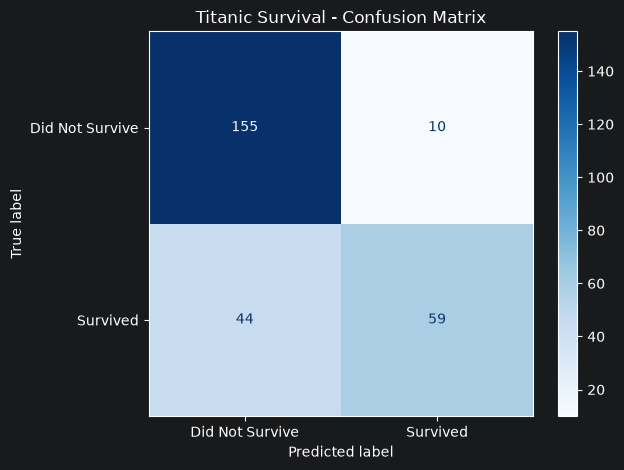

In [11]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot(cmap="Blues")

plt.title("Titanic Survival - Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
results = X_test.copy()

results["Actual"] = y_test
results["Predicted"] = y_pred

errors = results[
    results["Actual"] != results["Predicted"]
].copy()

print("Total incorrect predictions:", len(errors))

print("\nIncorrect predictions by actual outcome:")
print(errors["Actual"].value_counts())

print("\nExample incorrect predictions:")
print(errors.head(10))

# Determine which error type was more common
false_survivors = (
    (results["Actual"] == 0) &
    (results["Predicted"] == 1)
).sum()

missed_survivors = (
    (results["Actual"] == 1) &
    (results["Predicted"] == 0)
).sum()

print("\nPredicted survived but did not:", false_survivors)
print("Predicted did not survive but survived:", missed_survivors)

if false_survivors > missed_survivors:
    print("Most common error: predicting survival for passengers who died.")
elif missed_survivors > false_survivors:
    print("Most common error: predicting death for passengers who survived.")
else:
    print("Both error types occurred equally often.")

Total incorrect predictions: 54

Incorrect predictions by actual outcome:
Actual
1    44
0    10
Name: count, dtype: int64

Example incorrect predictions:
     Pclass   Age  Sex     Fare  Actual  Predicted
804       3  27.0    0   6.9750       1          0
338       3  45.0    0   8.0500       1          0
431       3  29.0    1  16.1000       1          0
549       2   8.0    0  36.7500       1          0
430       1  28.0    0  26.5500       1          0
216       3  27.0    1   7.9250       1          0
17        2  29.0    0  13.0000       1          0
205       3   2.0    1  10.4625       0          1
489       3   9.0    0  15.9000       1          0
347       3  29.0    1  16.1000       1          0

Predicted survived but did not: 10
Predicted did not survive but survived: 44
Most common error: predicting death for passengers who survived.


In [13]:
# I created a Decision tree Classifier to predict Titanic passenger survival using passenger class, age, sex, and fare. I cleaned the dataset by converting categorical values into numerical values and replacing missing ages with the training median.